In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('branch_performance.csv')
df

,Month,Branch,Revenue,Expenses,Customer_Visits,Sales_Target
0,2026-01,Ahmedabad,450000,310000,1200,430000
1,2026-01,Surat,390000,275000,1050,400000
2,2026-01,Vadodara,320000,230000,900,340000
3,2026-01,Rajkot,280000,205000,760,300000
4,2026-02,Ahmedabad,480000,325000,1280,450000
5,2026-02,Surat,410000,285000,1100,410000
6,2026-02,Vadodara,350000,245000,940,350000
7,2026-02,Rajkot,295000,212000,790,305000
8,2026-03,Ahmedabad,510000,340000,1350,470000
9,2026-03,Surat,430000,298000,1160,420000


In [4]:
df.isnull().sum()

Month              0
Branch             0
Revenue            0
Expenses           0
Customer_Visits    0
Sales_Target       0
dtype: int64

In [5]:
df.shape

(12, 6)

In [7]:
df.dtypes

Month                str
Branch               str
Revenue            int64
Expenses           int64
Customer_Visits    int64
Sales_Target       int64
dtype: object

In [8]:
df.describe()

,Revenue,Expenses,Customer_Visits,Sales_Target
count,12.000000,12.000000,12.000000,12.000000
mean,382083.333333,266250.000000,1026.666667,378333.333333
std,75240.775132,45829.972329,195.184450,59096.736309
min,280000.000000,205000.000000,760.000000,300000.000000
25%,317500.000000,227500.000000,880.000000,332500.000000
50%,375000.000000,262500.000000,1010.000000,377500.000000
75%,435000.000000,301000.000000,1170.000000,422500.000000
max,510000.000000,340000.000000,1350.000000,470000.000000


In [9]:
df['Month'] = pd.to_datetime(df['Month'],format='mixed')

In [10]:
df

,Month,Branch,Revenue,Expenses,Customer_Visits,Sales_Target
0,2026-01-01,Ahmedabad,450000,310000,1200,430000
1,2026-01-01,Surat,390000,275000,1050,400000
2,2026-01-01,Vadodara,320000,230000,900,340000
3,2026-01-01,Rajkot,280000,205000,760,300000
4,2026-02-01,Ahmedabad,480000,325000,1280,450000
5,2026-02-01,Surat,410000,285000,1100,410000
6,2026-02-01,Vadodara,350000,245000,940,350000
7,2026-02-01,Rajkot,295000,212000,790,305000
8,2026-03-01,Ahmedabad,510000,340000,1350,470000
9,2026-03-01,Surat,430000,298000,1160,420000


In [11]:
df.dtypes

Month              datetime64[us]
Branch                        str
Revenue                     int64
Expenses                    int64
Customer_Visits             int64
Sales_Target                int64
dtype: object

In [13]:
df['Profit'] = df['Revenue'] - df['Expenses']

In [ ]:
df.head(2)

,Month,Branch,Revenue,Expenses,Customer_Visits,Sales_Target,Profit
0,2026-01-01,Ahmedabad,450000,310000,1200,430000,140000
1,2026-01-01,Surat,390000,275000,1050,400000,115000


In [16]:
df['Profit_Margin'] = (df['Profit'] / df['Revenue']) * 100

In [17]:
df.head(2)

,Month,Branch,Revenue,Expenses,Customer_Visits,Sales_Target,Profit,Profit_Margin
0,2026-01-01,Ahmedabad,450000,310000,1200,430000,140000,31.111111
1,2026-01-01,Surat,390000,275000,1050,400000,115000,29.487179


In [18]:
df['Target_Achivement'] = (df['Revenue'] / df['Sales_Target']) * 100

In [19]:
df.head(2)

,Month,Branch,Revenue,Expenses,Customer_Visits,Sales_Target,Profit,Profit_Margin,Target_Achivement
0,2026-01-01,Ahmedabad,450000,310000,1200,430000,140000,31.111111,104.651163
1,2026-01-01,Surat,390000,275000,1050,400000,115000,29.487179,97.500000


In [20]:
branch_summary = df.groupby('Branch').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit_Margin=('Profit_Margin', 'mean'),
    Total_Customer_Visits=('Customer_Visits', 'sum')
)

print(branch_summary)

           Total_Revenue  Total_Profit  Average_Profit_Margin  \
Branch                                                          
Ahmedabad        1440000        465000              32.245370   
Rajkot            885000        248000              27.984522   
Surat            1230000        372000              30.224220   
Vadodara         1030000        305000              29.560185   

           Total_Customer_Visits  
Branch                            
Ahmedabad                   3830  
Rajkot                      2370  
Surat                       3310  
Vadodara                    2810  


In [21]:
pivot = pd.pivot_table(
    df,
    values='Revenue',
    index='Branch',
    columns='Month',
    aggfunc='sum'
)

pivot

Month,2026-01-01,2026-02-01,2026-03-01
Branch,,,
Ahmedabad,450000,480000,510000
Rajkot,280000,295000,310000
Surat,390000,410000,430000
Vadodara,320000,350000,360000


In [24]:
df[df['Target_Achivement'] == df['Target_Achivement'].min()]

,Month,Branch,Revenue,Expenses,Customer_Visits,Sales_Target,Profit,Profit_Margin,Target_Achivement
3,2026-01-01,Rajkot,280000,205000,760,300000,75000,26.785714,93.333333


In [25]:
df[df['Target_Achivement'] == df['Target_Achivement'].max()]

,Month,Branch,Revenue,Expenses,Customer_Visits,Sales_Target,Profit,Profit_Margin,Target_Achivement
8,2026-03-01,Ahmedabad,510000,340000,1350,470000,170000,33.333333,108.510638


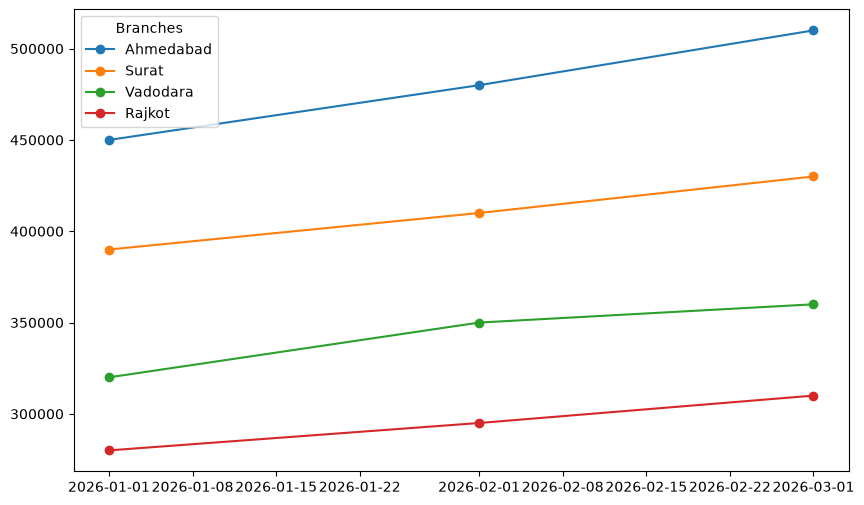

In [29]:
plt.figure(figsize=(10, 6))

for i in df['Branch'].unique():
    branch_data = df[df['Branch'] == i ]
    plt.plot(
    branch_data['Month'],
    branch_data['Revenue'],
    marker='o',
    label=i
    )

plt.legend(title="Branches")

In [ ]:
plt.figure(figsize=(10,6))

plt.bar(
    df['Total']
)